In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import math
from tensorflow.keras import layers
import pandas as pd

In [ ]:
data = pd.read_csv('modified_data5.csv')

In [ ]:
data.columns = ['x']

In [ ]:
print(data)

      Unnamed: 0    x    y
0              0 -237  0.0
1              1 -231  0.0
2              2 -231  1.0
3              3 -239  0.0
4              4 -251  0.0
...          ...  ...  ...
2201        2201 -218  0.0
2202        2202 -213  0.0
2203        2203 -210  0.0
2204        2204 -209  1.0
2205        2205 -216  NaN

[2206 rows x 3 columns]


#config

In [ ]:
nsamples = 2206      # Number of samples to use as a dataset
val_ratio = 0.2     # Percentage of samples that should be held for validation set
test_ratio = 0.2    # Percentage of samples that should be held for test set
tflite_model_name = 'sine_model'  # Will be given .tflite suffix
c_model_name = 'sine_model'       # Will be given .h suffix

#data split

In [ ]:
val_split = int(val_ratio * nsamples)
test_split = int(val_split + (test_ratio * nsamples))
x_val, x_test, x_train = np.split(data['x'], [val_split, test_split])
y_val, y_test, y_train = np.split(data['y'], [val_split, test_split])

/usr/local/lib/python3.10/dist-packages/numpy/core/fromnumeric.py:59: FutureWarning: 'Series.swapaxes' is deprecated and will be removed in a future version. Please use 'Series.transpose' instead.
  return bound(*args, **kwds)


In [ ]:
assert(x_train.size + x_val.size + x_test.size) == nsamples


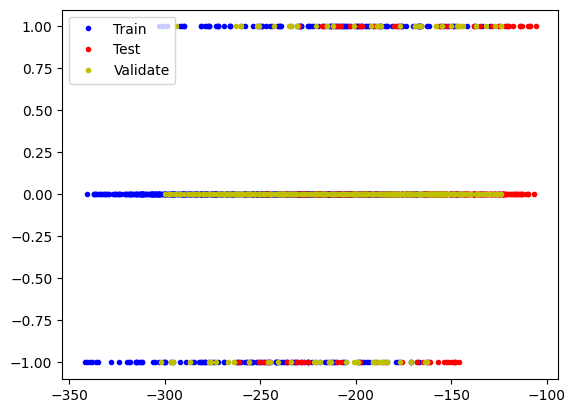

In [ ]:
plt.plot(x_train, y_train, 'b.', label="Train")
plt.plot(x_test, y_test, 'r.', label="Test")
plt.plot(x_val, y_val, 'y.', label="Validate")
plt.legend()
plt.show()

In [ ]:
#create model
model = tf.keras.Sequential()
model.add(layers.Dense(16, activation='relu', input_shape=(1,)))
model.add(layers.Dense(16, activation='relu'))
model.add(layers.Dense(1))


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Add optimizer, loss function, and metrics to model and compile it
model.compile(optimizer='rmsprop', loss='mae', metrics=['mae'])

In [ ]:
# Train model
history = model.fit(x_train,
                    y_train,
                    epochs=500,
                    batch_size=100,
                    validation_data=(x_val, y_val))

Epoch 1/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 2/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 3/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 4/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 5/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 6/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 7/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 8/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 9/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 10/500
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - 

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


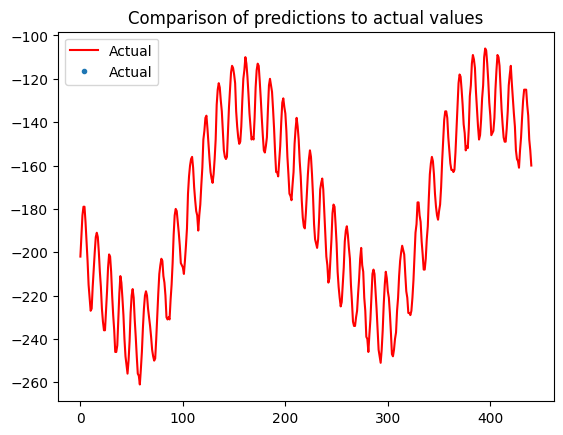

In [ ]:
# Plot predictions against actual values
predictions = model.predict(x_test)

plt.clf()
plt.title("Comparison of predictions to actual values")
#plt.plot(len(predictions), predictions, 'b', label='Prediction')
plt.plot(range(len(x_test-100)),x_test , 'r', label='Actual')
#plt.plot(range(len(y_test)),y_test , 'b', label='Actual')
plt.plot(range(len(predictions)),predictions-100 , '.', label='Actual')


plt.legend()
plt.show()


In [ ]:
# Convert Keras model to a tflite model
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.OPTIMIZE_FOR_SIZE]
tflite_model = converter.convert()

open(tflite_model_name + '.tflite', 'wb').write(tflite_model)

NameError: name 'tf' is not defined

In [ ]:
# Function: Convert some hex value into an array for C programming
def hex_to_c_array(hex_data, var_name):

  c_str = ''

  # Create header guard
  c_str += '#ifndef ' + var_name.upper() + '_H\n'
  c_str += '#define ' + var_name.upper() + '_H\n\n'

  # Add array length at top of file
  c_str += '\nunsigned int ' + var_name + '_len = ' + str(len(hex_data)) + ';\n'

  # Declare C variable
  c_str += 'unsigned char ' + var_name + '[] = {'
  hex_array = []
  for i, val in enumerate(hex_data) :

    # Construct string from hex
    hex_str = format(val, '#04x')

    # Add formatting so each line stays within 80 characters
    if (i + 1) < len(hex_data):
      hex_str += ','
    if (i + 1) % 12 == 0:
      hex_str += '\n '
    hex_array.append(hex_str)

  # Add closing brace
  c_str += '\n ' + format(' '.join(hex_array)) + '\n};\n\n'

  # Close out header guard
  c_str += '#endif //' + var_name.upper() + '_H'

  return c_str

In [ ]:
# Write TFLite model to a C source (or header) file
with open(c_model_name + '.h', 'w') as file:
  file.write(hex_to_c_array(tflite_model, c_model_name))